# Fig 2 — Methylation (250 kb bins): single-cell NOMe-HiC vs bulk WGBS ground truth

Compares **single-cell NOMe-HiC** endogenous CpG methylation (**HCG** context, GCG removed)
against **bulk WGBS** ground truth in **GM12878** and **IMR90**, at **250 kb bins**.

**Pipeline**
1. Bulk differential 250 kb tiles (HCG) are called with **methylKit** (`codes/dmr_methylkit_250kb.R`)
   → `analysis/dmr_250kb_hcg/{diffmeth_250kb_hcg_all.txt.gz, per_tile_methylation_250kb_hcg.txt.gz}`.
2. Single-cell HCG methylation at 250 kb bins: `…/QC/methylation_matrices/methylation_matrix_HCG_250kb.tsv.gz`.
3. Cell-type labels (GM12878 / IMR90): `…/metadata_with_cell_type.txt.gz`.
4. Heatmap: single cells (top, faceted by cell type) + bulk reference (bottom) over the top differential tiles.

Run with the **R (scnomehic)** kernel (or scnomehic_diff). Values are β (0–1).

In [2]:
suppressPackageStartupMessages({
  library(ggplot2); library(patchwork); library(scales); library(data.table)
})
set.seed(42)

FIG2   <- "/gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/fig2"
SCROOT <- "/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline"
DMR    <- file.path(FIG2, "analysis/dmr_250kb_hcg")
OUTFIG <- file.path(FIG2, "analysis/dmr_250kb_hcg/figures")
dir.create(OUTFIG, showWarnings = FALSE, recursive = TRUE)

# tunables
N_TOP_BIN <- 100       # total differential bins shown (split hyper/hypo)
QVAL      <- 0.05     # methylKit significance
DIFF_MIN  <- 10       # |meth.diff| % minimum for the differential set


## 1. Single-cell HCG matrix (cells × 250 kb bins) + cell-type labels

In [24]:
# single-cell HCG methylation matrix: rows = cells, cols = bins "chr1:1-250000"
hcg_path <- file.path(SCROOT, "snakemake/QC/methylation_matrices/methylation_matrix_HCG_250kb.tsv.gz")
sc <- as.data.frame(fread(hcg_path), check.names = FALSE)
rownames(sc) <- sc[[1]]; sc[[1]] <- NULL
sc <- as.matrix(sc)                       # cells x bins, beta 0..1
cat("sc HCG matrix (cells x bins):", dim(sc), "\n")

# cell-type labels (GM12878/IMR90) for these cells — saved assignment that
# matches the HCG matrix cell naming (batch1_sc1.ACTTGA ...).
lab_path <- file.path(SCROOT, "snakemake/subset_clustering/250kb/annotation/cell_type_table.tsv")
lab <- as.data.frame(fread(lab_path))                 # columns: cell, cell_type
ct  <- setNames(lab$cell_type, lab$cell)
sc <- sc[rownames(sc) %in% names(ct), , drop = FALSE]
cell_ct <- ct[rownames(sc)]
cat("labelled cells:", nrow(sc), "\n"); print(table(cell_ct))


sc HCG matrix (cells x bins): 640 12366 
labelled cells: 441 
cell_ct
GM12878   IMR90 
    281     160 


## 2. Bulk WGBS ground truth + methylKit differential 250 kb tiles

In [25]:
# methylKit per-tile bulk methylation (percent 0..100 -> beta 0..1)
per_tile <- as.data.frame(fread(file.path(DMR, "per_tile_methylation_250kb_hcg.txt.gz")))
per_tile$bin <- sprintf("%s:%d-%d", per_tile$chr, per_tile$start, per_tile$end)
per_tile$GM_beta  <- per_tile$GM12878_mean / 100
per_tile$IMR_beta <- per_tile$IMR90_mean   / 100

# methylKit differential test for all tiles (meth.diff = IMR90 - GM12878, percent)
dm <- as.data.frame(fread(file.path(DMR, "diffmeth_250kb_hcg_all.txt.gz")))
dm$bin <- sprintf("%s:%d-%d", dm$chr, dm$start, dm$end)
cat("bulk tiles:", nrow(per_tile), " | diffmeth tiles:", nrow(dm), "\n")


bulk tiles: 11378  | diffmeth tiles: 11378 


## 3. Align bins (single-cell ∩ bulk) and select top differential tiles

In [26]:
shared <- Reduce(intersect, list(colnames(sc), per_tile$bin, dm$bin))
cat("shared bins (sc ∩ bulk ∩ diffmeth):", length(shared), "\n")

dm_s <- dm[match(shared, dm$bin), ]
pt_s <- per_tile[match(shared, per_tile$bin), ]

sig <- dm_s[!is.na(dm_s$qvalue) & dm_s$qvalue < QVAL & abs(dm_s$meth.diff) >= DIFF_MIN, ]
n_each <- N_TOP_BIN %/% 2L
hyper <- sig[sig$meth.diff > 0, ]; hyper <- hyper[order(-hyper$meth.diff), ]   # IMR90 > GM
hypo  <- sig[sig$meth.diff < 0, ]; hypo  <- hypo[order(hypo$meth.diff), ]      # IMR90 < GM
top_bins <- c(head(hyper$bin, n_each), head(hypo$bin, n_each))
top_bins <- top_bins[order(dm_s$meth.diff[match(top_bins, dm_s$bin)], decreasing = TRUE)]
cat(sprintf("sig tiles q<%.2g & |Δ|>=%d: %d (hyperIMR %d / hypoIMR %d); showing %d\n",
            QVAL, DIFF_MIN, nrow(sig), nrow(hyper), nrow(hypo), length(top_bins)))


shared bins (sc ∩ bulk ∩ diffmeth): 11365 
sig tiles q<0.05 & |Δ|>=10: 769 (hyperIMR 696 / hypoIMR 73); showing 100


## 4. Heatmap — single cells (top) + bulk WGBS reference (bottom) over differential tiles

`meth_heatmap(bins)` builds the panel for any tile set, so we can redraw it after the
direction-consistency filter in 4b.

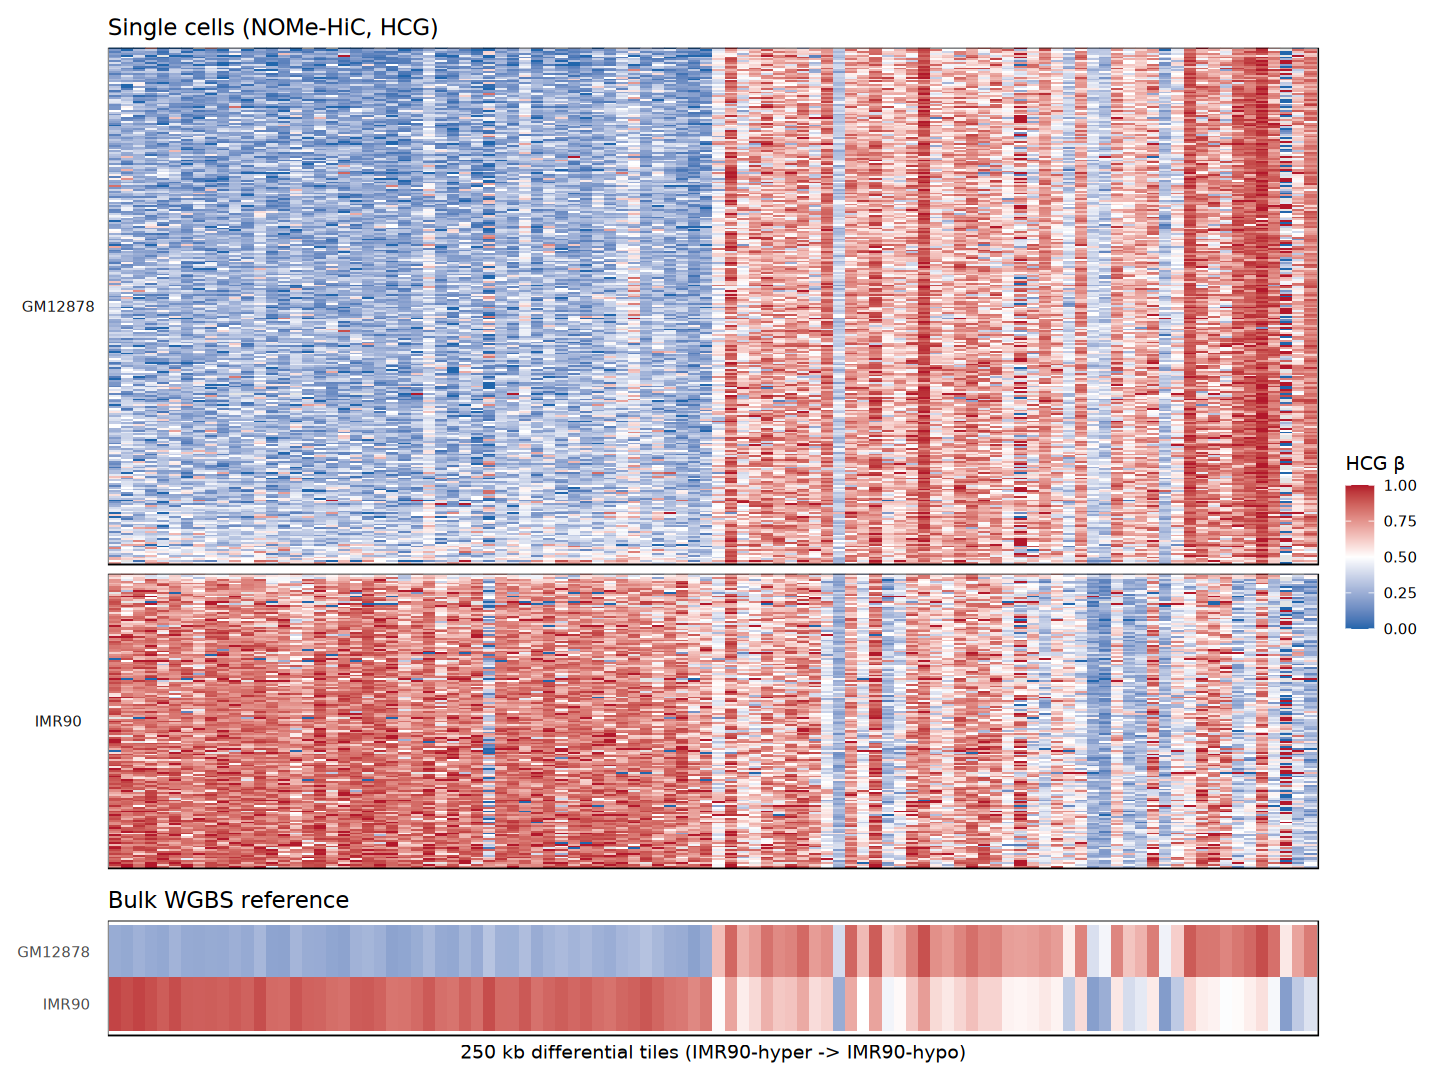

In [27]:
fill_scale <- scale_fill_gradient2(low = "#2166AC", mid = "white", high = "#B2182B",
                                   midpoint = 0.5, limits = c(0,1), na.value = "grey90",
                                   name = expression("HCG "*beta), oob = scales::squish)
tile_theme <- theme(
  axis.text.x = element_blank(), axis.ticks.x = element_blank(),
  axis.text.y = element_blank(), axis.ticks.y = element_blank(),
  panel.grid = element_blank(), panel.background = element_blank(),
  panel.border = element_rect(colour = "black", fill = NA, linewidth = 0.4),
  strip.background = element_blank(), legend.position = "right")

# build the single-cell (top) + bulk-WGBS (bottom) heatmap panel for a set of bins
meth_heatmap <- function(bins, sc_title = "Single cells (NOMe-HiC, HCG)") {
  sc_b <- sc[, bins, drop = FALSE]
  ord  <- order(factor(cell_ct, levels = c("GM12878","IMR90")), rowMeans(sc_b, na.rm = TRUE))
  co   <- rownames(sc_b)[ord]; cto <- cell_ct[co]
  sc_long <- data.frame(
    cell = factor(rep(co, times = length(bins)), levels = rev(co)),
    bin  = factor(rep(bins, each = length(co)), levels = bins),
    beta = as.numeric(sc_b[co, bins]),
    cell_type = factor(rep(cto, times = length(bins)), levels = c("GM12878","IMR90")))
  bulk_long <- data.frame(
    ref  = factor(rep(c("GM12878","IMR90"), each = length(bins)), levels = c("IMR90","GM12878")),
    bin  = factor(rep(bins, times = 2), levels = bins),
    beta = c(pt_s$GM_beta[match(bins, pt_s$bin)], pt_s$IMR_beta[match(bins, pt_s$bin)]))
  p_sc <- ggplot(sc_long, aes(bin, cell, fill = beta)) + geom_tile() + fill_scale +
    facet_grid(cell_type ~ ., scales = "free_y", space = "free_y", switch = "y") +
    labs(title = sc_title, x = NULL, y = NULL) + tile_theme +
    theme(strip.text.y.left = element_text(angle = 0, face = "bold"), strip.placement = "outside")
  p_bulk <- ggplot(bulk_long, aes(bin, ref, fill = beta)) + geom_tile() + fill_scale +
    labs(title = "Bulk WGBS reference",
         x = "250 kb differential tiles (IMR90-hyper -> IMR90-hypo)", y = NULL) +
    tile_theme + theme(axis.text.y = element_text(face = "bold"))
  (p_sc / p_bulk) + plot_layout(heights = c(10, 1.4), guides = "collect")
}

hm_all <- meth_heatmap(top_bins)
ggsave(file.path(OUTFIG, "fig2_methylation_250kb_heatmap.pdf"), hm_all, width = 12, height = 9)
options(repr.plot.width = 12, repr.plot.height = 9); hm_all


## 4b. Direction-consistency filter — keep only tiles where single cells agree with bulk

For each differential tile we compare the **bulk** direction (methylKit `meth.diff` = IMR90 − GM12878)
to the **single-cell** direction (pseudobulk IMR90 − GM12878 over the labelled cells). Tiles whose
single-cell direction disagrees with the bulk DMR call are dropped, and the heatmap is redrawn on the
consistent set only.

Direction-consistent tiles: 82 / 100 (82.0%)
Variance cap SD<=16: dropped 19 noisy of 82 consistent
Kept 24/direction (lowest sc-variance) -> 48 tiles (24 hyper / 24 hypo); dropped 15 of 63 consistent


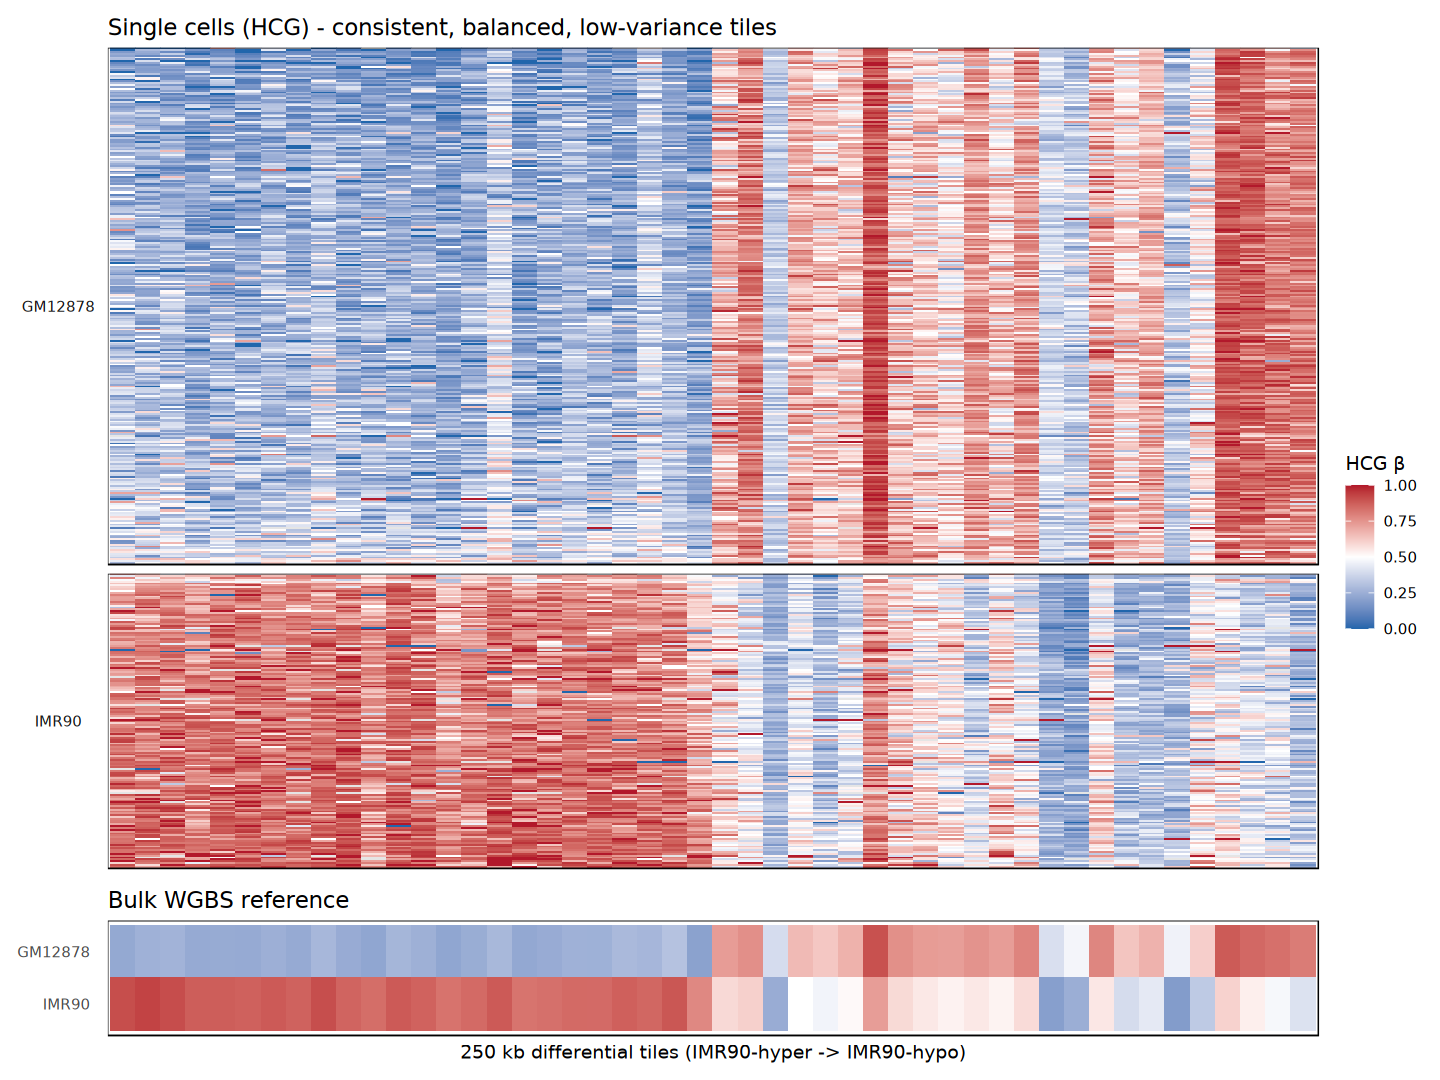

In [28]:
# ---- 4b tunables (self-contained; independent of cell-1 thresholds) ----
N_PER_DIR <- NA   # tiles kept PER direction; NA = balance to the smaller direction's count
SD_MAX    <- 16   # drop tiles whose single-cell SD (max of GM/IMR cells, beta*100) > this; Inf = off

# 1) direction consistency: single-cell (pseudobulk IMR90-GM12878) vs bulk meth.diff sign
sc_imr <- colMeans(sc[cell_ct=="IMR90",   top_bins, drop=FALSE], na.rm=TRUE)
sc_gm  <- colMeans(sc[cell_ct=="GM12878", top_bins, drop=FALSE], na.rm=TRUE)
sc_delta   <- sc_imr - sc_gm                              # single-cell IMR90 - GM12878 (beta)
bulk_delta <- dm_s$meth.diff[match(top_bins, dm_s$bin)]  # bulk   IMR90 - GM12878 (percent)
consistent <- sign(sc_delta) == sign(bulk_delta)
cat(sprintf("Direction-consistent tiles: %d / %d (%.1f%%)\n",
            sum(consistent), length(top_bins), 100*mean(consistent)))
cons <- top_bins[consistent]

# 2) single-cell WITHIN-GROUP variance per tile = MAX of GM-cell & IMR-cell variance
#    (max, not mean, so a tile noisy in EITHER cell type is penalised); lower = cleaner
sc_var <- pmax(apply(sc[cell_ct=="GM12878", cons, drop=FALSE], 2, var, na.rm=TRUE),
               apply(sc[cell_ct=="IMR90",   cons, drop=FALSE], 2, var, na.rm=TRUE))

# 2b) absolute variance cap: drop tiles too noisy in EITHER cell type, in EITHER direction
#     (this is what trims the minority/hypo side; balancing alone keeps all minority tiles).
drop_noisy <- 100*sqrt(sc_var) > SD_MAX
cat(sprintf("Variance cap SD<=%.0f: dropped %d noisy of %d consistent\n",
            SD_MAX, sum(drop_noisy), length(cons)))
cons   <- cons[!drop_noisy]
sc_var <- sc_var[cons]

# 3) balance directions + drop higher-variance tiles:
#    keep the lowest-variance N_PER_DIR tiles in EACH direction, subsetting the larger
#    (more-tile) side down to the smaller (less-tile) side's count.
bd    <- dm_s$meth.diff[match(cons, dm_s$bin)]
hyper <- cons[bd > 0]; hypo <- cons[bd < 0]
n_keep <- if (is.na(N_PER_DIR)) min(length(hyper), length(hypo)) else N_PER_DIR
keep_lowvar <- function(b) if (length(b)) b[order(sc_var[b])][seq_len(min(n_keep, length(b)))] else b
sel <- c(keep_lowvar(hyper), keep_lowvar(hypo))
sel <- sel[order(dm_s$meth.diff[match(sel, dm_s$bin)], decreasing = TRUE)]   # display order
cat(sprintf("Kept %d/direction (lowest sc-variance) -> %d tiles (%d hyper / %d hypo); dropped %d of %d consistent\n",
            n_keep, length(sel),
            sum(dm_s$meth.diff[match(sel, dm_s$bin)] > 0),
            sum(dm_s$meth.diff[match(sel, dm_s$bin)] < 0),
            length(cons) - length(sel), length(cons)))

# 4) redraw heatmap on the consistent + balanced + low-variance tile set
stopifnot(length(sel) >= 1)
hm_consistent <- meth_heatmap(sel,
                  sc_title = "Single cells (HCG) - consistent, balanced, low-variance tiles")
ggsave(file.path(OUTFIG, "fig2_methylation_250kb_heatmap_consistent.pdf"),
       hm_consistent, width = 12, height = 9)
options(repr.plot.width = 12, repr.plot.height = 9); hm_consistent


## 4c. Pseudobulk heatmap + ground-truth delta

Read-weighted single-cell **pseudobulk** HCG (Σ methylated reads / Σ total reads per 250 kb bin
per cell type, from `sc_pseudobulk_HCG_250kb.tsv.gz`) shown as 2 rows (GM12878, IMR90) over the
§4b-selected tiles, with the bulk **WGBS ground truth collapsed to a single Δβ (IMR90 − GM12878)**
reference row — like the final figure in the accessibility notebook.

pseudobulk delta-beta vs bulk delta-beta over 48 shown tiles: r=0.965


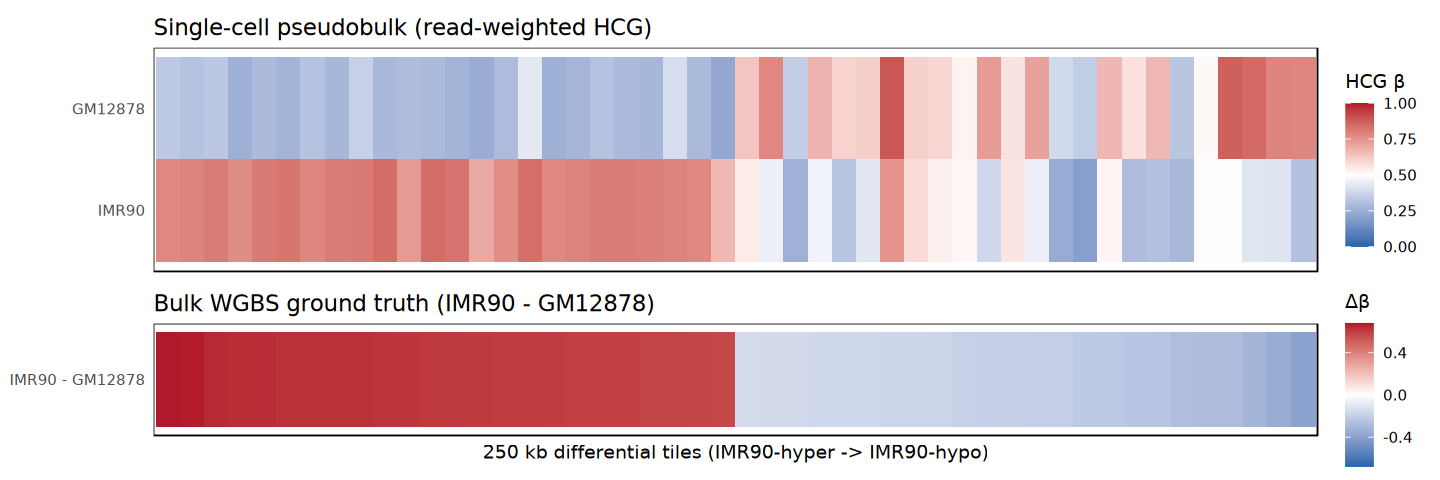

In [30]:
# read-weighted single-cell pseudobulk HCG (sum meth / sum reads per 250kb bin per cell type)
pbk <- as.data.frame(fread(file.path(DMR, "sc_pseudobulk_HCG_250kb.tsv.gz")))
bins_show <- if (exists("sel")) sel else top_bins      # use the 4b-selected tiles (else top_bins)

# --- top panel: pseudobulk beta, 2 rows (GM12878, IMR90); same beta scale as the 4 heatmap ---
pb_long <- data.frame(
  ref  = factor(rep(c("GM12878","IMR90"), each = length(bins_show)), levels = c("IMR90","GM12878")),
  bin  = factor(rep(bins_show, times = 2), levels = bins_show),
  beta = c(pbk$GM12878_beta[match(bins_show, pbk$bin_id)],
           pbk$IMR90_beta[match(bins_show, pbk$bin_id)]))
p_pb <- ggplot(pb_long, aes(bin, ref, fill = beta)) + geom_tile() + fill_scale +
  labs(title = "Single-cell pseudobulk (read-weighted HCG)", x = NULL, y = NULL) +
  tile_theme + theme(axis.text.y = element_text(face = "bold"))

# --- bottom panel: bulk WGBS ground truth as ONE delta row (IMR90 - GM12878) ---
gt_delta <- pt_s$IMR_beta[match(bins_show, pt_s$bin)] - pt_s$GM_beta[match(bins_show, pt_s$bin)]
gt_long  <- data.frame(ref = factor("IMR90 - GM12878"),
                       bin = factor(bins_show, levels = bins_show), delta = gt_delta)
dlim <- max(abs(gt_delta), na.rm = TRUE)
p_gt <- ggplot(gt_long, aes(bin, ref, fill = delta)) + geom_tile() +
  scale_fill_gradient2(low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 0,
                       limits = c(-dlim, dlim), oob = scales::squish, name = expression(Delta*beta)) +
  labs(title = "Bulk WGBS ground truth (IMR90 - GM12878)",
       x = "250 kb differential tiles (IMR90-hyper -> IMR90-hypo)", y = NULL) +
  tile_theme + theme(axis.text.y = element_text(face = "bold"))

# concordance: pseudobulk delta vs bulk delta over the shown tiles
pb_delta <- pbk$IMR90_beta[match(bins_show, pbk$bin_id)] - pbk$GM12878_beta[match(bins_show, pbk$bin_id)]
cat(sprintf("pseudobulk delta-beta vs bulk delta-beta over %d shown tiles: r=%.3f\n",
            length(bins_show), cor(pb_delta, gt_delta, use = "complete.obs")))

comb_pb <- (p_pb / p_gt) + plot_layout(heights = c(2, 1))
ggsave(file.path(OUTFIG, "fig2_methylation_250kb_pseudobulk_delta.pdf"), comb_pb, width = 12, height = 4)
options(repr.plot.width = 12, repr.plot.height = 4); comb_pb


## 4d. Pseudobulk as two separate panels + ground-truth delta

Same read-weighted pseudobulk, but GM12878 and IMR90 are drawn as **two separate single-row
heatmaps** (each its own panel), stacked above the bulk WGBS Δβ (IMR90 − GM12878) reference row.

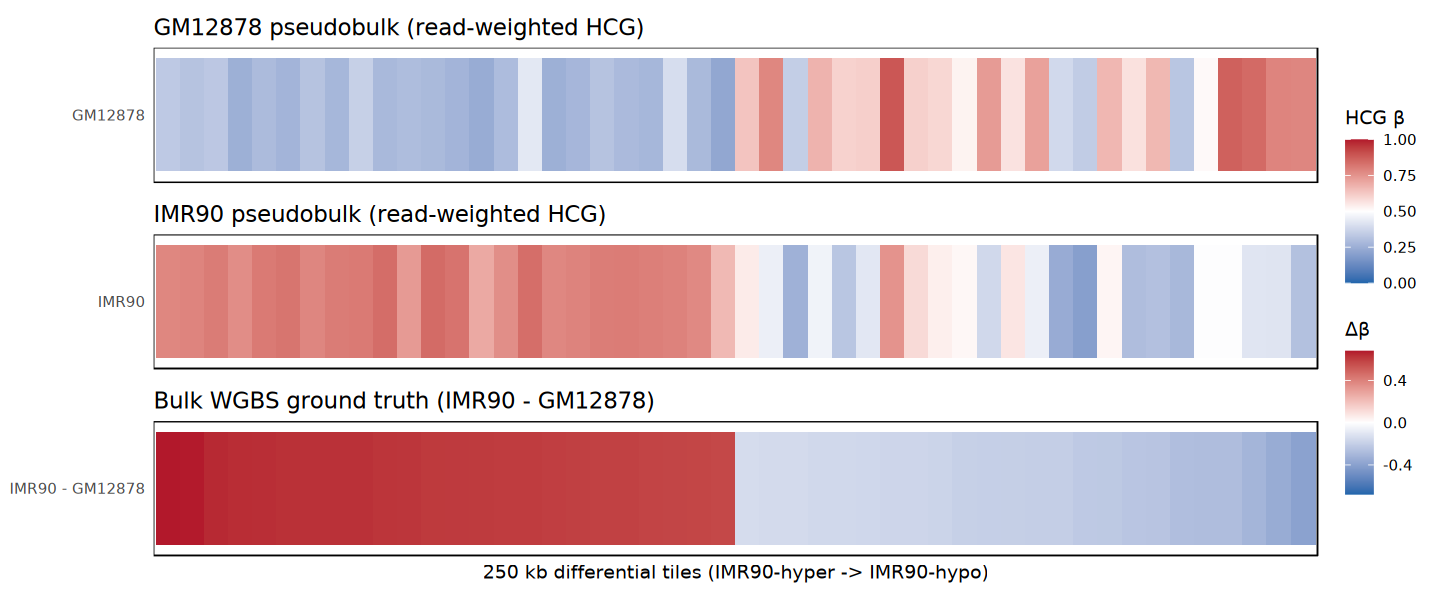

In [31]:
bins_show <- if (exists("sel")) sel else top_bins
if (!exists("pbk")) pbk <- as.data.frame(fread(file.path(DMR, "sc_pseudobulk_HCG_250kb.tsv.gz")))

# --- pseudobulk drawn as TWO SEPARATE panels (one per cell type) ---
mk_pb_panel <- function(beta_vec, ttl, lab) {
  d <- data.frame(ref = factor(lab),
                  bin = factor(bins_show, levels = bins_show), beta = beta_vec)
  ggplot(d, aes(bin, ref, fill = beta)) + geom_tile() + fill_scale +
    labs(title = ttl, x = NULL, y = NULL) +
    tile_theme + theme(axis.text.y = element_text(face = "bold"))
}
p_gm  <- mk_pb_panel(pbk$GM12878_beta[match(bins_show, pbk$bin_id)], "GM12878 pseudobulk (read-weighted HCG)", "GM12878")
p_imr <- mk_pb_panel(pbk$IMR90_beta[match(bins_show, pbk$bin_id)],   "IMR90 pseudobulk (read-weighted HCG)", "IMR90")

# --- bulk WGBS ground truth: single delta row (IMR90 - GM12878) ---
gt_delta <- pt_s$IMR_beta[match(bins_show, pt_s$bin)] - pt_s$GM_beta[match(bins_show, pt_s$bin)]
gt_long  <- data.frame(ref = factor("IMR90 - GM12878"),
                       bin = factor(bins_show, levels = bins_show), delta = gt_delta)
dlim <- max(abs(gt_delta), na.rm = TRUE)
p_gt <- ggplot(gt_long, aes(bin, ref, fill = delta)) + geom_tile() +
  scale_fill_gradient2(low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 0,
                       limits = c(-dlim, dlim), oob = scales::squish, name = expression(Delta*beta)) +
  labs(title = "Bulk WGBS ground truth (IMR90 - GM12878)",
       x = "250 kb differential tiles (IMR90-hyper -> IMR90-hypo)", y = NULL) +
  tile_theme + theme(axis.text.y = element_text(face = "bold"))

comb_sep <- (p_gm / p_imr / p_gt) + plot_layout(heights = c(1, 1, 1), guides = "collect")
ggsave(file.path(OUTFIG, "fig2_methylation_250kb_pseudobulk_separate.pdf"), comb_sep, width = 12, height = 5)
options(repr.plot.width = 12, repr.plot.height = 5); comb_sep


## 5. Concordance — single-cell pseudobulk vs bulk (per cell type)

Pearson r  sc-pseudobulk vs bulk:  GM=0.933  IMR=0.882


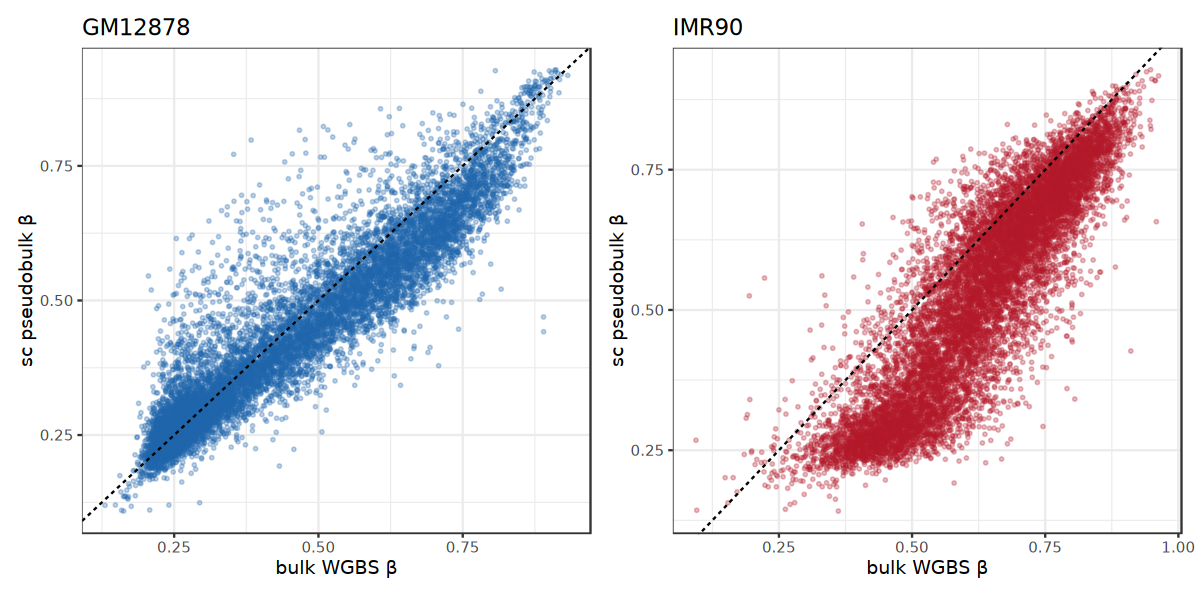

In [7]:
# pseudobulk by cell type over ALL shared bins, correlate to bulk
pb_gm  <- colMeans(sc[cell_ct=="GM12878", shared, drop=FALSE], na.rm = TRUE)
pb_imr <- colMeans(sc[cell_ct=="IMR90",   shared, drop=FALSE], na.rm = TRUE)
cc <- data.frame(bin = shared,
                 sc_GM = pb_gm, sc_IMR = pb_imr,
                 bulk_GM = pt_s$GM_beta, bulk_IMR = pt_s$IMR_beta)
cat(sprintf("Pearson r  sc-pseudobulk vs bulk:  GM=%.3f  IMR=%.3f\n",
            cor(cc$sc_GM, cc$bulk_GM, use="complete.obs"),
            cor(cc$sc_IMR, cc$bulk_IMR, use="complete.obs")))

p1 <- ggplot(cc, aes(bulk_GM, sc_GM))  + geom_point(alpha=.3, size=.6, colour="#2166AC") +
  geom_abline(linetype=2) +
  labs(title="GM12878", x=expression("bulk WGBS "*beta), y=expression("sc pseudobulk "*beta)) + theme_bw()
p2 <- ggplot(cc, aes(bulk_IMR, sc_IMR)) + geom_point(alpha=.3, size=.6, colour="#B2182B") +
  geom_abline(linetype=2) +
  labs(title="IMR90", x=expression("bulk WGBS "*beta), y=expression("sc pseudobulk "*beta)) + theme_bw()
sc_pb <- p1 | p2
ggsave(file.path(OUTFIG, "fig2_methylation_250kb_concordance.pdf"), sc_pb, width = 10, height = 5)
options(repr.plot.width = 10, repr.plot.height = 5); sc_pb


## 6. From-scratch selection by pseudobulk-vs-ground-truth agreement

Independent of the methylKit per-tile test: over **all** 250 kb bins, compute the read-weighted
single-cell pseudobulk Δβ (IMR90 − GM12878) and the bulk WGBS Δβ, keep bins that are (a) covered,
(b) clearly differential, and (c) **direction-consistent** between pseudobulk and bulk. Plots the
pseudobulk-vs-bulk Δβ trend (scatter) and the selected tiles as a heatmap (pseudobulk two panels +
bulk Δβ row). Tunables are local to this cell.

covered bins (>=20 reads/type): 11365 ; pseudobulk-vs-bulk Δβ r=0.748
consistent & differential: 5090 (4974 hyper / 116 hypo); showing 100


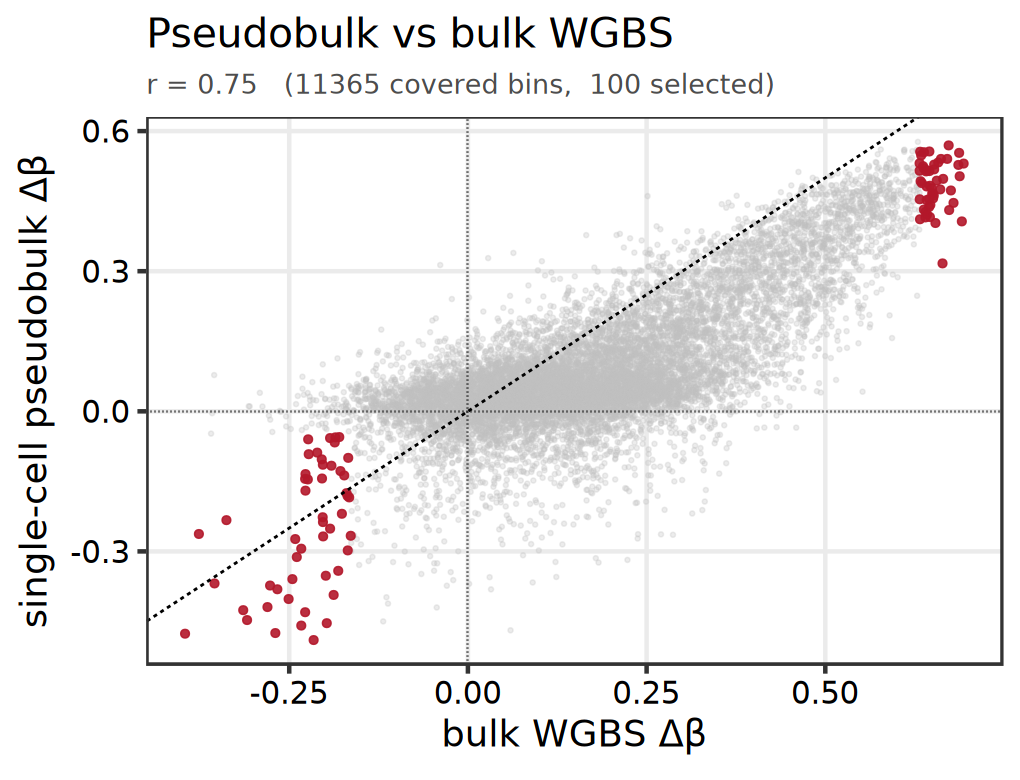

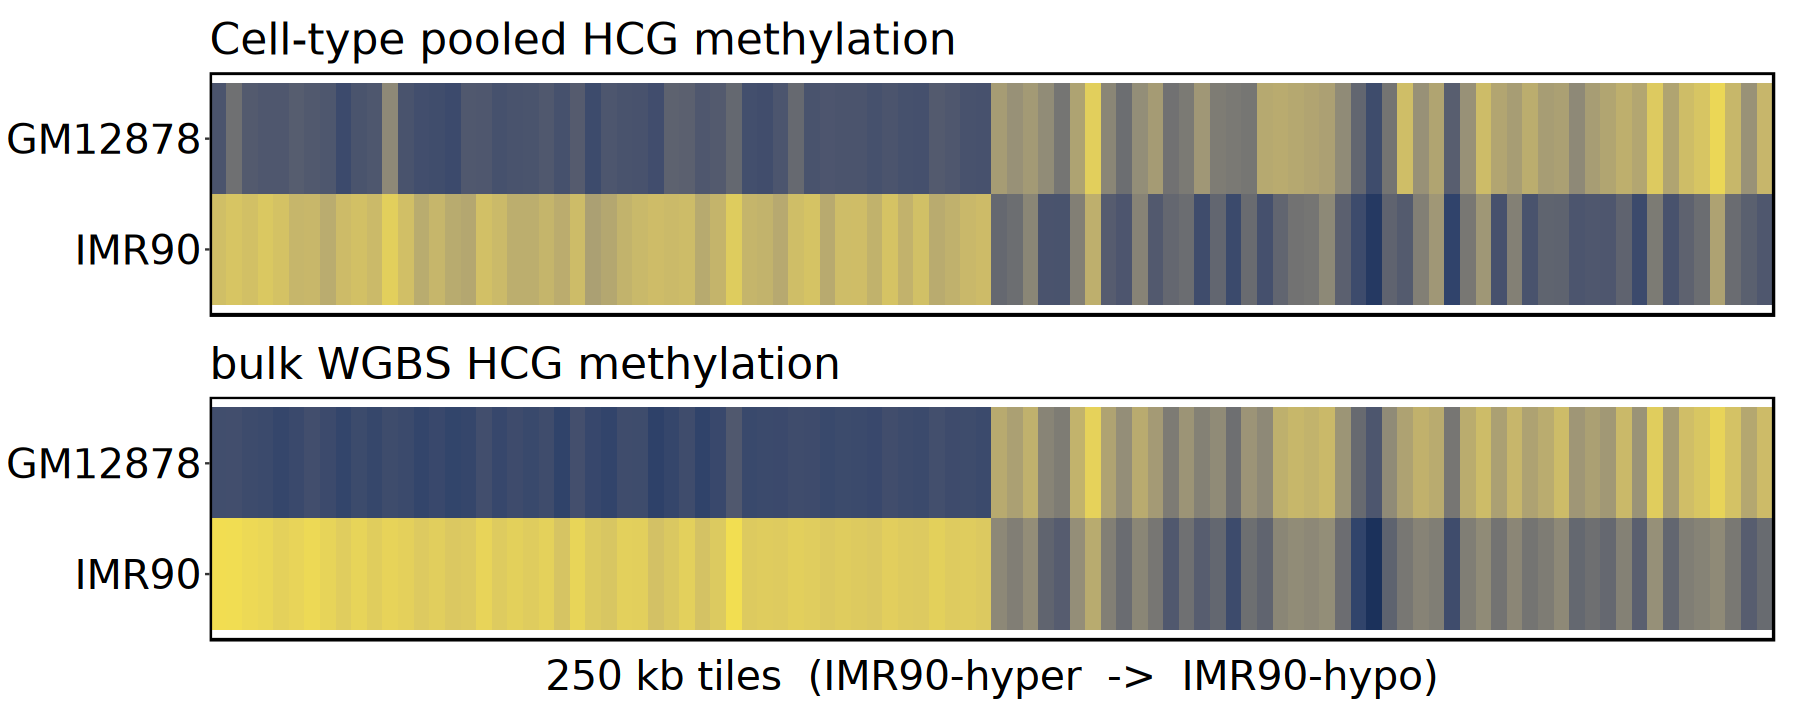

In [42]:
# ---- tunables (local; from-scratch, does NOT use top_bins / sel) ----
PB_MIN_READS <- 20     # min pooled reads per cell type per bin to trust the pseudobulk value
DELTA_MIN    <- 0.10   # min |bulk WGBS Δβ| for a "differential" bin
PB_DELTA_MIN <- 0.05   # min |pseudobulk Δβ|
N_SHOW       <- 100     # tiles shown in the heatmap (balanced hyper/hypo)

if (!exists("pbk")) pbk <- as.data.frame(fread(file.path(DMR, "sc_pseudobulk_HCG_250kb.tsv.gz")))
if (!exists("fill_scale")) fill_scale <- scale_fill_gradient2(low="#2166AC", mid="white", high="#B2182B",
  midpoint=0.5, limits=c(0,1), na.value="grey90", name=expression("HCG "*beta), oob=scales::squish)
meth_scale <- scale_fill_viridis_c(option = "cividis", limits = c(0,1), na.value = "grey90",
  name = expression("HCG "*beta), oob = scales::squish)   # blue = low, yellow = high methylation
if (!exists("tile_theme")) tile_theme <- theme(axis.text.x=element_blank(), axis.ticks.x=element_blank(),
  panel.grid=element_blank(), panel.background=element_blank(),
  panel.border=element_rect(colour="black", fill=NA, linewidth=0.4),
  strip.background=element_blank(), legend.position="right")

# merge pseudobulk + bulk WGBS over ALL bins (per_tile carries bulk GM_beta/IMR_beta from cell 2)
M <- merge(pbk, per_tile[, c("bin","GM_beta","IMR_beta")], by.x="bin_id", by.y="bin")
M$pb_delta   <- M$IMR90_beta - M$GM12878_beta     # single-cell pseudobulk IMR90 - GM12878
M$bulk_delta <- M$IMR_beta - M$GM_beta            # bulk WGBS IMR90 - GM12878
M <- M[M$GM12878_total >= PB_MIN_READS & M$IMR90_total >= PB_MIN_READS &
       is.finite(M$pb_delta) & is.finite(M$bulk_delta), ]
cat(sprintf("covered bins (>=%d reads/type): %d ; pseudobulk-vs-bulk Δβ r=%.3f\n",
            PB_MIN_READS, nrow(M), cor(M$pb_delta, M$bulk_delta)))

# consistent (same sign) AND clearly differential in BOTH
sel6 <- M[sign(M$pb_delta)==sign(M$bulk_delta) &
          abs(M$bulk_delta)>=DELTA_MIN & abs(M$pb_delta)>=PB_DELTA_MIN, ]
n_each <- N_SHOW %/% 2L
hy <- sel6[sel6$bulk_delta>0, ]; hy <- hy[order(-abs(hy$bulk_delta)), ]   # IMR90-hyper
ho <- sel6[sel6$bulk_delta<0, ]; ho <- ho[order(-abs(ho$bulk_delta)), ]   # IMR90-hypo
bins6 <- c(head(hy$bin_id, n_each), head(ho$bin_id, n_each))
bins6 <- bins6[order(M$bulk_delta[match(bins6, M$bin_id)], decreasing=TRUE)]
cat(sprintf("consistent & differential: %d (%d hyper / %d hypo); showing %d\n",
            nrow(sel6), sum(sel6$bulk_delta>0), sum(sel6$bulk_delta<0), length(bins6)))

# ---- publication theme: larger text ----
pub_tile <- theme(
  axis.text.x  = element_blank(), axis.ticks.x = element_blank(),
  axis.text.y  = element_text(size = 24, face = "bold", colour = "black"),
  axis.title.x = element_text(size = 24, margin = margin(t = 9)),
  panel.grid = element_blank(), panel.background = element_blank(),
  panel.border = element_rect(colour = "black", fill = NA, linewidth = 1.1),
  plot.title = element_text(size = 26, face = "bold"),
  strip.background = element_blank(),
  legend.position = "none",                 # no color bar
  plot.margin = margin(8, 10, 8, 10))

# --- (a) trend scatter (publication) ---
M$selected <- M$bin_id %in% bins6
p_sc6 <- ggplot(M[order(M$selected), ], aes(bulk_delta, pb_delta, colour = selected)) +
  geom_point(aes(size = selected, alpha = selected)) +
  geom_abline(linetype = 2, linewidth = 0.6) +
  geom_hline(yintercept = 0, linetype = 3) + geom_vline(xintercept = 0, linetype = 3) +
  scale_colour_manual(values = c("FALSE"="grey75","TRUE"="#B2182B"), guide = "none") +
  scale_size_manual(values = c("FALSE"=0.8,"TRUE"=1.8), guide = "none") +
  scale_alpha_manual(values = c("FALSE"=0.3,"TRUE"=0.9), guide = "none") +
  labs(title = "Pseudobulk vs bulk WGBS",
       subtitle = sprintf("r = %.2f   (%d covered bins,  %d selected)", cor(M$pb_delta, M$bulk_delta), nrow(M), length(bins6)),
       x = expression("bulk WGBS "*Delta*beta),
       y = expression("single-cell pseudobulk "*Delta*beta)) +
  theme_bw(base_size = 21) +
  theme(plot.title = element_text(face = "bold", size = 24),
        plot.subtitle = element_text(size = 16, colour = "grey30"),
        axis.title = element_text(size = 22),
        axis.text  = element_text(size = 18, colour = "black"),
        panel.grid.minor = element_blank(),
        legend.position = "none")
ggsave(file.path(OUTFIG, "fig2_methylation_250kb_fromscratch_scatter.pdf"), p_sc6, width = 8.5, height = 6.5)

# --- (b) heatmap of selected tiles (publication): pseudobulk 2 rows + bulk delta row ---
pb_long6 <- data.frame(
  ref  = factor(rep(c("GM12878","IMR90"), each = length(bins6)), levels = c("IMR90","GM12878")),
  bin  = factor(rep(bins6, times = 2), levels = bins6),
  beta = c(M$GM12878_beta[match(bins6, M$bin_id)], M$IMR90_beta[match(bins6, M$bin_id)]))
p_pb6 <- ggplot(pb_long6, aes(bin, ref, fill = beta)) + geom_tile() + meth_scale +
  labs(title = "Cell-type pooled HCG methylation", x = NULL, y = NULL) + pub_tile
# ground truth: bulk WGBS as TWO rows (GM12878, IMR90) beta -- same scale as the pooled panel
bulk_long6 <- data.frame(
  ref  = factor(rep(c("GM12878","IMR90"), each = length(bins6)), levels = c("IMR90","GM12878")),
  bin  = factor(rep(bins6, times = 2), levels = bins6),
  beta = c(M$GM_beta[match(bins6, M$bin_id)], M$IMR_beta[match(bins6, M$bin_id)]))
p_gt6 <- ggplot(bulk_long6, aes(bin, ref, fill = beta)) + geom_tile() + meth_scale +
  labs(title = "bulk WGBS HCG methylation",
       x = "250 kb tiles  (IMR90-hyper  ->  IMR90-hypo)", y = NULL) + pub_tile
comb6 <- (p_pb6 / p_gt6) + plot_layout(heights = c(1, 1))
ggsave(file.path(OUTFIG, "fig2_methylation_250kb_fromscratch_heatmap.pdf"), comb6, width = 15, height = 6)

options(repr.plot.width = 8.5, repr.plot.height = 6.5); print(p_sc6)
options(repr.plot.width = 15, repr.plot.height = 6); print(comb6)


## 7. Metilene de-novo DMRs — load & characterize

Loads the metilene de-novo DMR output (`analysis/dmr_metilene_hcg/metilene_GM12878_IMR90.dmr.txt`,
all DMRs that passed the calling floors `-m 10 -d 0.1`) and characterizes them: length, #CpGs,
methylation difference (meandiff = **GM12878 − IMR90**), group means, and significance.
Mirrors metilene_output.pl's basic plots, inline.

metilene DMRs: 213578 total | 32236 GM12878-hyper | 181342 IMR90-hyper
length: median 448 bp (IQR 248-691) | #CpGs: median 10 | q<0.05: 76126


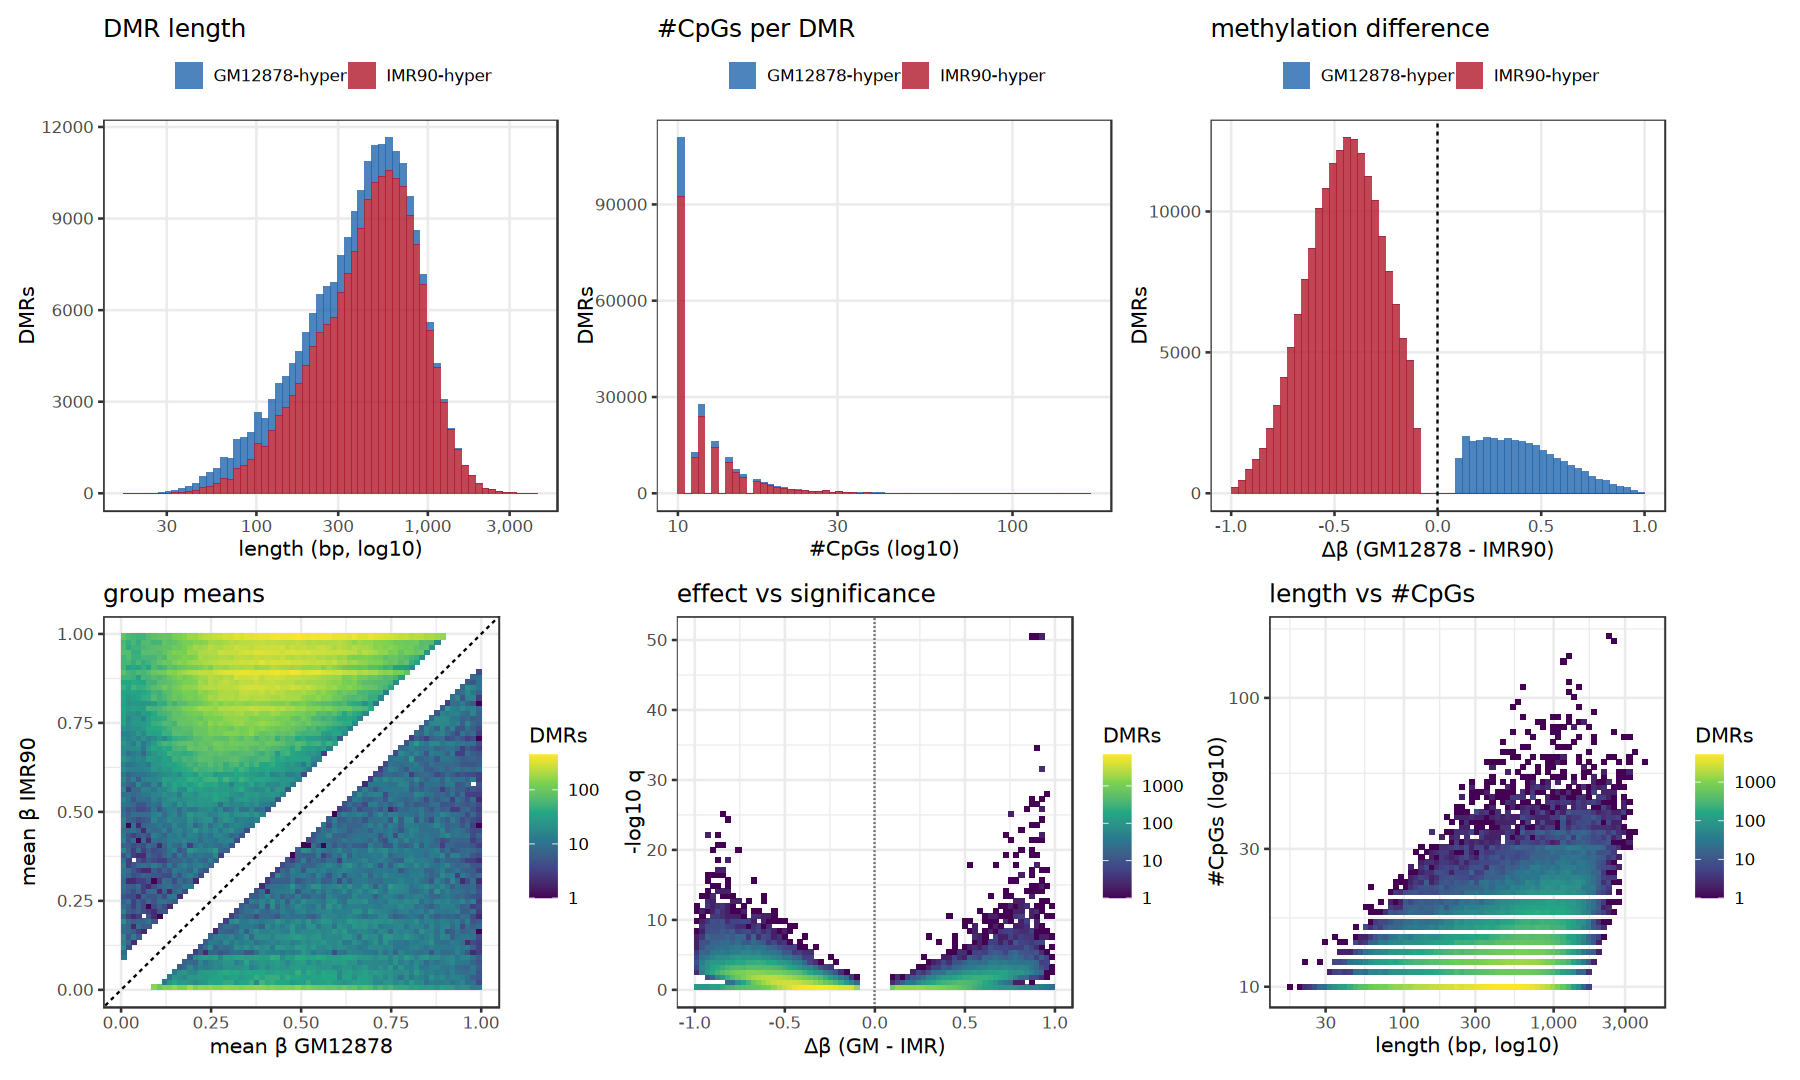

In [45]:
library(data.table); library(ggplot2); library(patchwork); library(scales)
MET_DMR <- file.path(FIG2, "analysis/dmr_metilene_hcg/metilene_GM12878_IMR90.dmr.txt")
met <- fread(MET_DMR, header = FALSE,
  col.names = c("chr","start","stop","qvalue","meandiff","nCpG","p_MWU","p_2DKS","mean_GM","mean_IMR"))
met[, length := stop - start]
met[, absdiff := abs(meandiff)]
met[, dir := ifelse(meandiff > 0, "GM12878-hyper", "IMR90-hyper")]   # meandiff = GM - IMR
cat(sprintf("metilene DMRs: %d total | %d GM12878-hyper | %d IMR90-hyper\n",
            nrow(met), sum(met$meandiff>0), sum(met$meandiff<0)))
cat(sprintf("length: median %d bp (IQR %d-%d) | #CpGs: median %d | q<0.05: %d\n",
            median(met$length), quantile(met$length,.25), quantile(met$length,.75),
            median(met$nCpG), sum(met$qvalue<0.05)))

dir_cols <- c("GM12878-hyper"="#2166AC", "IMR90-hyper"="#B2182B")
th <- theme_bw(base_size = 12) + theme(panel.grid.minor = element_blank(), legend.position = "top")

p_len <- ggplot(met, aes(length, fill = dir)) + geom_histogram(bins = 60, alpha = .8) +
  scale_x_log10(labels = comma) + scale_fill_manual(values = dir_cols, name = NULL) +
  labs(title = "DMR length", x = "length (bp, log10)", y = "DMRs") + th
p_cpg <- ggplot(met, aes(nCpG, fill = dir)) + geom_histogram(bins = 60, alpha = .8) +
  scale_x_log10() + scale_fill_manual(values = dir_cols, name = NULL) +
  labs(title = "#CpGs per DMR", x = "#CpGs (log10)", y = "DMRs") + th
p_diff <- ggplot(met, aes(meandiff, fill = dir)) + geom_histogram(bins = 60, alpha = .8) +
  geom_vline(xintercept = 0, linetype = 2) + scale_fill_manual(values = dir_cols, name = NULL) +
  labs(title = "methylation difference", x = expression(Delta*beta*" (GM12878 - IMR90)"), y = "DMRs") + th
p_mm <- ggplot(met, aes(mean_GM, mean_IMR)) + geom_bin2d(bins = 70) +
  scale_fill_viridis_c(trans = "log10", name = "DMRs") + geom_abline(linetype = 2) +
  labs(title = "group means", x = expression("mean "*beta*" GM12878"), y = expression("mean "*beta*" IMR90")) + theme_bw(base_size = 12)
p_vol <- ggplot(met, aes(meandiff, -log10(qvalue + 1e-300))) + geom_bin2d(bins = 70) +
  scale_fill_viridis_c(trans = "log10", name = "DMRs") + geom_vline(xintercept = 0, linetype = 3) +
  labs(title = "effect vs significance", x = expression(Delta*beta*" (GM - IMR)"), y = "-log10 q") +
  theme_bw(base_size = 12)
p_lc <- ggplot(met, aes(length, nCpG)) + geom_bin2d(bins = 70) +
  scale_fill_viridis_c(trans = "log10", name = "DMRs") + scale_x_log10(labels = comma) + scale_y_log10() +
  labs(title = "length vs #CpGs", x = "length (bp, log10)", y = "#CpGs (log10)") + theme_bw(base_size = 12)

charac <- (p_len | p_cpg | p_diff) / (p_mm | p_vol | p_lc)
ggsave(file.path(FIG2, "analysis/dmr_metilene_hcg/metilene_DMR_characterization.pdf"),
       charac, width = 15, height = 9)
options(repr.plot.width = 15, repr.plot.height = 9); charac


## 7b. DMR counts under different filter criteria

How many DMRs survive combinations of significance (q-value) and effect-size (|Δβ|) cutoffs, split by
direction. (All DMRs already satisfy the calling floors #CpGs ≥ 10 and |Δβ| ≥ 0.1.) Use this to pick a
reference set for plotting.

  qval dabs total GM_hyper IMR_hyper
 0.001  0.1 14057     2030     12027
 0.001  0.2 14057     2030     12027
 0.001  0.3 14036     2026     12010
 0.001  0.5 12856     1877     10979
 0.010  0.1 41311     4878     36433
 0.010  0.2 41300     4878     36422
 0.010  0.3 41012     4843     36169
 0.010  0.5 34935     4203     30732
 0.050  0.1 76126     8483     67643
 0.050  0.2 75979     8467     67512
 0.050  0.3 74521     8317     66204
 0.050  0.5 56337     6402     49935


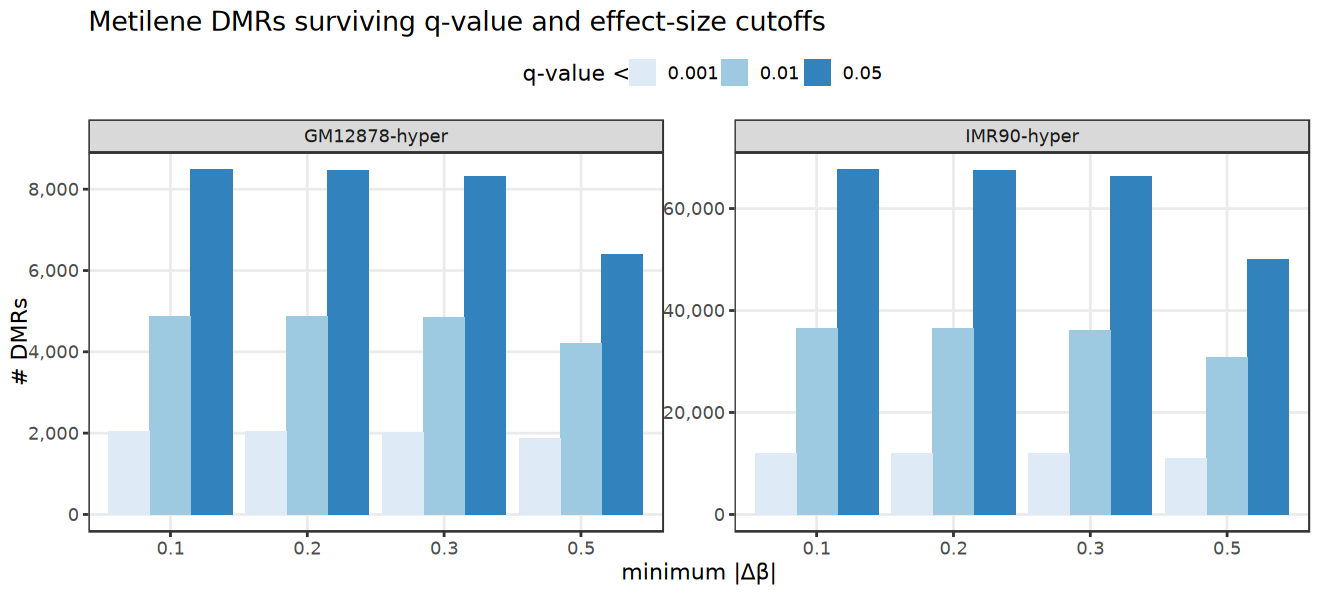

In [ ]:
qs <- c(0.05, 0.01, 0.001); ds <- c(0.1, 0.2, 0.3, 0.5)
grid <- expand.grid(qval = qs, dabs = ds)
res <- do.call(rbind, lapply(seq_len(nrow(grid)), function(i) {
  s <- met[qvalue < grid$qval[i] & absdiff >= grid$dabs[i]]
  data.frame(qval = grid$qval[i], dabs = grid$dabs[i],
             total = nrow(s), GM_hyper = sum(s$meandiff > 0), IMR_hyper = sum(s$meandiff < 0))
}))
print(res[order(res$qval, res$dabs), ], row.names = FALSE)

long <- rbind(
  data.frame(res, grp = "IMR90-hyper", n = res$IMR_hyper),
  data.frame(res, grp = "GM12878-hyper", n = res$GM_hyper))
p_crit <- ggplot(long, aes(factor(dabs), n, fill = factor(qval))) +
  geom_col(position = "dodge") +
  facet_wrap(~ grp, scales = "free_y") +
  scale_fill_brewer(palette = "Blues", name = "q-value <", direction = 1) +
  scale_y_continuous(labels = comma) +
  labs(title = "Metilene DMRs surviving q-value and effect-size cutoffs",
       x = expression("minimum |"*Delta*beta*"|"), y = "# DMRs") +
  theme_bw(base_size = 13) + theme(panel.grid.minor = element_blank(), legend.position = "top")
ggsave(file.path(FIG2, "analysis/dmr_metilene_hcg/metilene_DMR_criteria_counts.pdf"),
       p_crit, width = 11, height = 5)
options(repr.plot.width = 11, repr.plot.height = 5); p_crit


## 8. Metilene DMRs — single-cell pseudobulk: direction check + most-different DMRs

Loads `sc_pseudobulk_metilene_dmr_top2000.tsv.gz` (2000 IMR90-hyper + 2000 GM12878-hyper DMRs,
read-weighted sc pseudobulk per cell type + read counts). Steps: (1) coverage filter; (2) **check
direction** — does sc pseudobulk Δβ (IMR90−GM12878) agree in sign with the bulk DMR direction?
(scatter + %consistent); (3) among direction-consistent DMRs, **pick the most different ones**
(largest |sc Δβ|) per direction and plot pooled vs bulk WGBS (blue=low, yellow=high).

DMRs (cov>=20 both): 3890 | direction-consistent: 3804 (97.8%) | r(sc Δ, bulk Δ)=0.941
plotting 400 DMRs (200 IMR-hyper + 200 GM-hyper), most different by |sc Δβ|


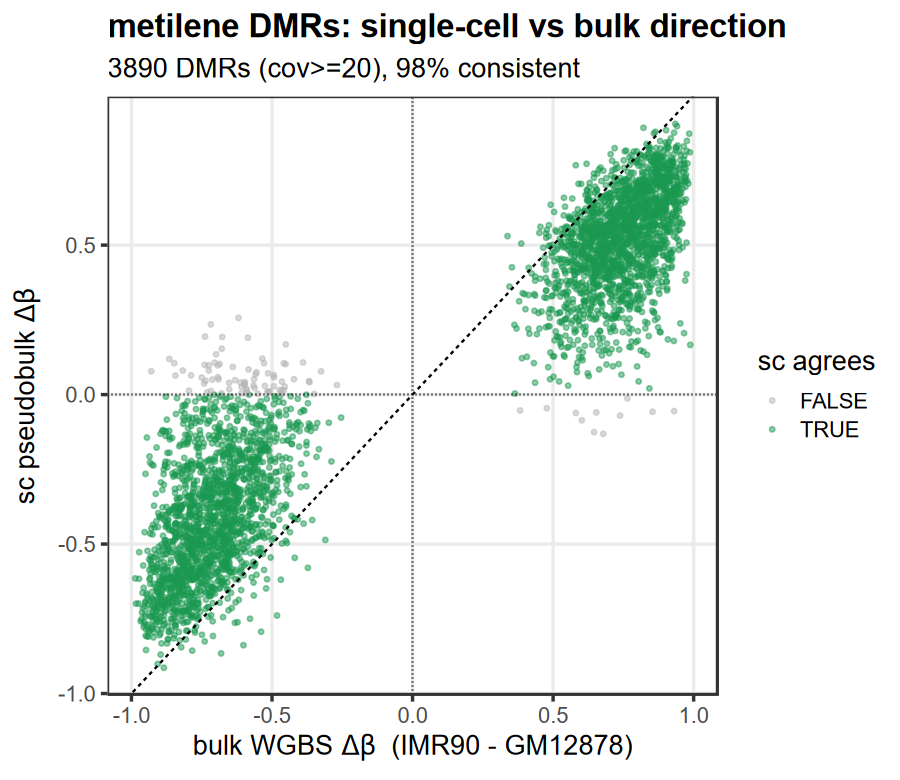

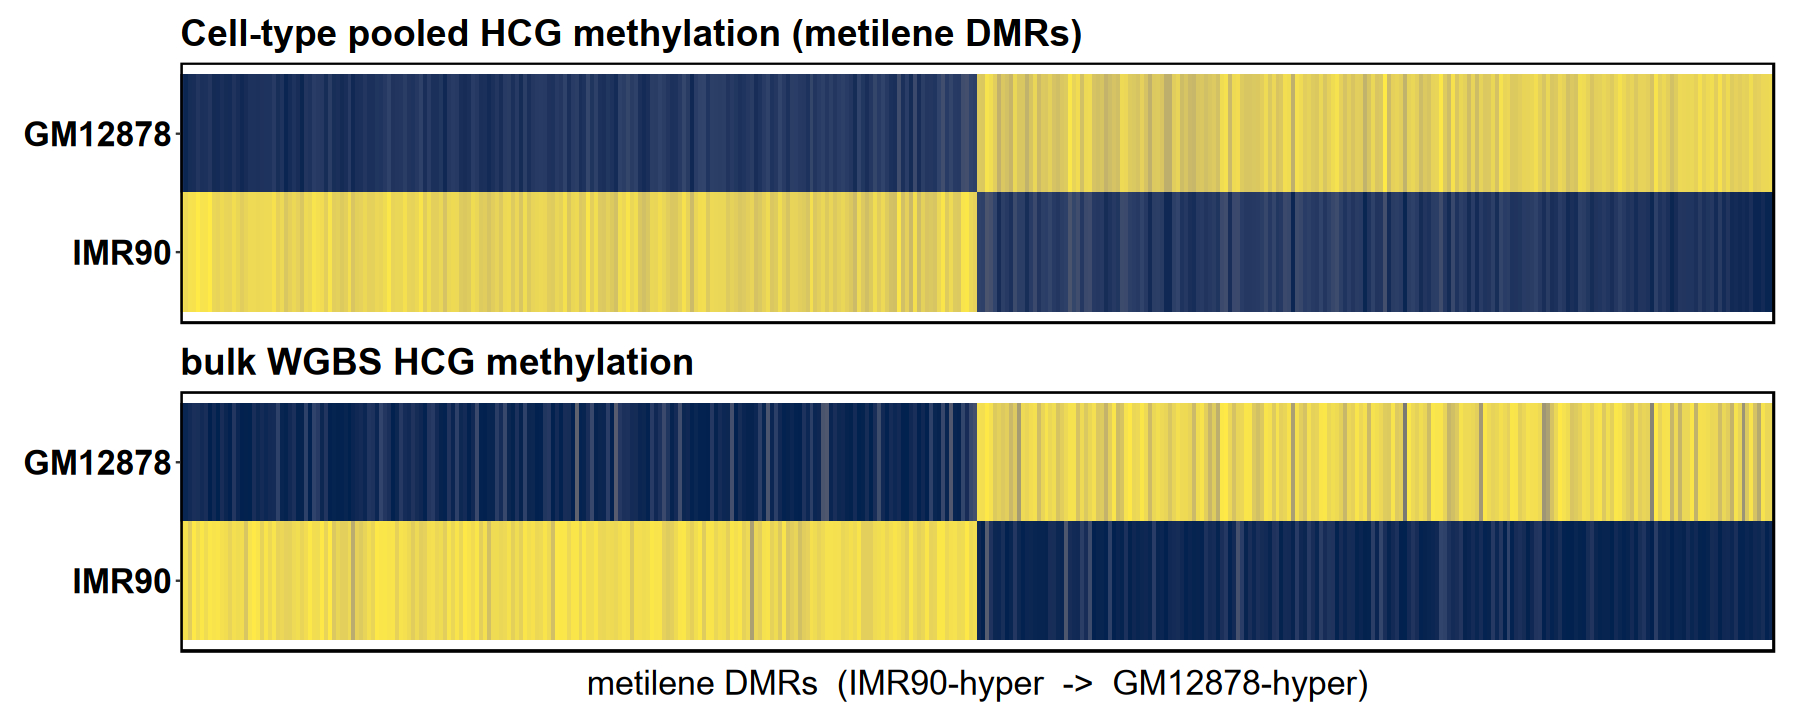

In [7]:
library(data.table); library(ggplot2); library(patchwork); library(scales)
mp <- as.data.frame(fread(file.path(FIG2,
        "analysis/dmr_metilene_hcg/sc_pseudobulk_metilene_dmr_top2000.tsv.gz")))

# ---- tunables ----
MIN_READS <- 20    # min pooled reads per cell type per DMR (coverage filter)
N_SHOW    <- 200   # DMRs per direction to plot (the most different by |sc Δβ|)

# coverage filter + deltas
mp <- mp[mp$GM12878_total >= MIN_READS & mp$IMR90_total >= MIN_READS, ]
mp$bulk_delta <- mp$bulk_mean_IMR - mp$bulk_mean_GM          # bulk WGBS IMR90 - GM12878
mp$sc_delta   <- mp$sc_delta_IMR_minus_GM                    # sc pseudobulk IMR90 - GM12878
mp$consistent <- sign(mp$sc_delta) == sign(mp$bulk_delta)
cat(sprintf("DMRs (cov>=%d both): %d | direction-consistent: %d (%.1f%%) | r(sc Δ, bulk Δ)=%.3f\n",
    MIN_READS, nrow(mp), sum(mp$consistent), 100*mean(mp$consistent),
    cor(mp$sc_delta, mp$bulk_delta, use="complete.obs")))

# ---- (1) direction check scatter ----
p_dir <- ggplot(mp, aes(bulk_delta, sc_delta, colour = consistent)) +
  geom_point(alpha = .5, size = .9) + geom_abline(linetype = 2) +
  geom_hline(yintercept = 0, linetype = 3) + geom_vline(xintercept = 0, linetype = 3) +
  scale_colour_manual(values = c("FALSE"="grey70","TRUE"="#1A9850"), name = "sc agrees") +
  labs(title = "metilene DMRs: single-cell vs bulk direction",
       subtitle = sprintf("%d DMRs (cov>=%d), %.0f%% consistent", nrow(mp), MIN_READS, 100*mean(mp$consistent)),
       x = expression("bulk WGBS "*Delta*beta*"  (IMR90 - GM12878)"),
       y = expression("sc pseudobulk "*Delta*beta)) +
  theme_bw(base_size = 16) + theme(plot.title=element_text(face="bold"), panel.grid.minor=element_blank())
ggsave(file.path(FIG2,"analysis/dmr_metilene_hcg/metilene_dmr_direction_scatter.pdf"), p_dir, width=7.5, height=6.5)
options(repr.plot.width=7.5, repr.plot.height=6.5); print(p_dir)

# ---- (2) pick most-different consistent DMRs (largest |sc Δβ|), per direction ----
cons <- mp[mp$consistent, ]; cons$absd <- abs(cons$sc_delta)
pick <- function(dr) { s <- cons[cons$dir==dr, ]; s[order(-s$absd), ][seq_len(min(N_SHOW, nrow(s))), ] }
selm <- rbind(pick("IMR90-hyper"), pick("GM12878-hyper"))
selm <- selm[order(-selm$sc_delta), ]                       # IMR90-hyper (Δ>0) left -> GM12878-hyper right
ids  <- selm$region_id
cat(sprintf("plotting %d DMRs (%d IMR-hyper + %d GM-hyper), most different by |sc Δβ|\n",
    length(ids), sum(selm$dir=="IMR90-hyper"), sum(selm$dir=="GM12878-hyper")))

# ---- (3) heatmap: pooled (top) + bulk WGBS (bottom), blue=low / yellow=high ----
meth_scale <- scale_fill_viridis_c(option="cividis", limits=c(0,1), na.value="grey90", oob=scales::squish)
pub_tile <- theme(axis.text.x=element_blank(), axis.ticks.x=element_blank(),
  axis.text.y=element_text(size=20, face="bold", colour="black"),
  axis.title.x=element_text(size=20, margin=margin(t=8)),
  panel.grid=element_blank(), panel.background=element_blank(),
  panel.border=element_rect(colour="black", fill=NA, linewidth=1.0),
  plot.title=element_text(size=22, face="bold"), legend.position="none", plot.margin=margin(6,10,6,10))
mk2 <- function(gmv, imrv, ttl) ggplot(
  data.frame(ref=factor(rep(c("GM12878","IMR90"), each=length(ids)), levels=c("IMR90","GM12878")),
             reg=factor(rep(ids, 2), levels=ids), beta=c(gmv, imrv)),
  aes(reg, ref, fill=beta)) + geom_tile() + meth_scale + labs(title=ttl, x=NULL, y=NULL) + pub_tile
p_pool <- mk2(selm$GM12878_beta, selm$IMR90_beta, "Cell-type pooled HCG methylation (metilene DMRs)")
p_bulk <- mk2(selm$bulk_mean_GM, selm$bulk_mean_IMR, "bulk WGBS HCG methylation") +
  labs(x="metilene DMRs  (IMR90-hyper  ->  GM12878-hyper)")
comb_m <- (p_pool / p_bulk) + plot_layout(heights=c(1,1))
ggsave(file.path(FIG2,"analysis/dmr_metilene_hcg/metilene_dmr_pseudobulk_heatmap.pdf"), comb_m, width=15, height=6)
options(repr.plot.width=15, repr.plot.height=6); comb_m


### 8b. Colorbar

The heatmaps are drawn with `legend.position = "none"`, so the colour scale is rendered here as a
standalone **horizontal colorbar**, in the same format/size as the accessibility notebook's 7d
`cbar()` (title above, 16pt ticks, 6.6 x 1.2 in per bar). Methylation needs only **one** bar — the
pooled and bulk WGBS panels share the identical HCG β scale (cividis: blue = low, yellow = high, 0–1).

wrote -> metilene_dmr_colorbar.pdf (6.6 x 1.2 in, one bar)


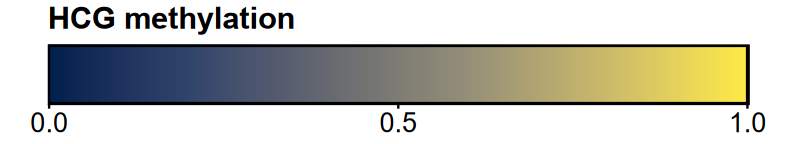

In [ ]:
# Colorbar in the same format/size as the accessibility notebook's 7d cbar():
# one bar only (pooled + bulk panels share the same HCG beta scale). 6.6 x 1.2 in = one 7d bar.
OUTM <- file.path(FIG2, "analysis/dmr_metilene_hcg")

cbar_meth <- function(lo = 0, hi = 1, title = "HCG methylation", fmt = "%.1f", n = 256) {
  d <- data.frame(x = seq(lo, hi, length.out = n), y = 1)
  ggplot(d, aes(x, y, fill = x)) + geom_raster() +
    scale_fill_viridis_c(option = "cividis", limits = c(lo, hi), guide = "none",
                         oob = scales::squish) +
    scale_x_continuous(breaks = c(lo, (lo+hi)/2, hi),
                       labels = function(b) sprintf(fmt, b), expand = c(0,0)) +
    scale_y_continuous(expand = c(0,0)) +
    labs(title = title, x = NULL, y = NULL) +
    theme(axis.text.x = element_text(size = 16, colour = "black"),
          axis.ticks.x = element_line(colour = "black"),
          axis.text.y = element_blank(), axis.ticks.y = element_blank(),
          panel.background = element_blank(), panel.grid = element_blank(),
          panel.border = element_rect(colour = "black", fill = NA, linewidth = 1.1),
          plot.title = element_text(size = 18, face = "bold"),
          plot.margin = margin(4, 26, 4, 26))
}

cb_meth <- cbar_meth(0, 1, "HCG methylation")
ggsave(file.path(OUTM, "metilene_dmr_colorbar.pdf"), cb_meth, width = 6.6, height = 1.2)
cat("wrote -> metilene_dmr_colorbar.pdf (6.6 x 1.2 in, one bar)\n")
options(repr.plot.width = 6.6, repr.plot.height = 1.2); cb_meth
